# NB. Linear Stability Analysis of the Asymptotic Suction Boundary Layer
## Modified Orr-Sommerfeld equation (2D, temporal stability)

> Adapted from the plane-channel-flow Orr&ndash;Sommerfeld notebook by<br>
  Philipp Schlatter<br>
  philipp.schlatter@fau.de and pschlatt@mech.kth.se<br>
  Institute of Fluid Mechanics (LSTM), Friedrich-Alexander-Universit&auml;t Erlangen-N&uuml;rnberg, Germany<br>
  KTH Engineering Mechanics, Royal Institute of Technology, Stockholm, Sweden<br>
  <br>
  Saleh Rezaeiravesh<br>
  saleh.rezaeiravesh@manchester.ac.uk<br>
> University of Manchester, UK<br><br>
> Original notebook: part of the [KTH-Nek5000 lecture notes](https://kth-nek5000.github.io/kthNekBook/).
> This version replaces the channel-flow problem with the **asymptotic suction boundary layer (ASBL)**:
> a semi-infinite domain, a base flow with a nonzero constant wall-normal (suction) velocity, and the
> resulting *modified* Orr&ndash;Sommerfeld equation this induces.


In [1]:
%matplotlib inline
import numpy as np
import scipy.linalg as scla
import matplotlib.pyplot as plt
from numpy.linalg import norm
import matplotlib.pylab as pylab
from chebdif import chebdif

params = {'legend.fontsize': 10,
          'legend.loc':'best',
          'figure.figsize': (6,4),
          'lines.markerfacecolor':'none',
          'axes.labelsize': 12,
          'axes.titlesize': 12,
          'xtick.labelsize':10,
          'ytick.labelsize':10,
          'grid.alpha':0.6}
pylab.rcParams.update(params)

## Modified Orr&ndash;Sommerfeld equation for a flow with wall-normal suction

Channel flow has a purely streamwise base flow, $U(y)$ only. The asymptotic suction boundary
layer (ASBL) additionally has a **nonzero, constant wall-normal base velocity** $\bar V$ (the
suction), and this changes the derivation of the Orr&ndash;Sommerfeld equation, not just the
profile plugged into it. Linearising the Navier&ndash;Stokes equations about the base state
$(U(y),\bar V,0)$ and eliminating $\hat u,\hat p$ exactly as before (Hocking 1975; Fransson &amp;
Alfredsson, *J. Fluid Mech.* **482**, 2003) gives one extra, odd-order term:

$$
(U-c)(\hat{v}'' -\alpha^2 \hat{v})-\hat{v} U''
\;+\;\frac{i}{\alpha}\bar V\left(\hat v'''-\alpha^2\hat v'\right)
=-\frac{i}{\alpha Re}(\hat{v}''''-2\alpha^2 \hat{v}'' +\alpha^4 \hat{v}) \,.
$$

With the differentiation operator $D=d/dy$, this is the generalised eigenvalue problem
$A\hat v=\omega B\hat v$ ($\omega=c\alpha$) with

$$
A =
\underbrace{-\frac{1}{Re}\left(D^4-2\alpha^2 D^2+\alpha^4 I\right) -i \alpha U'' + i\alpha U (D^2-\alpha^2I)}_{\text{same structure as channel flow}}
\;\;\underbrace{-\,\frac{1}{Re}\left(D^3-\alpha^2 D\right)}_{\text{new: suction term}}\,,
\qquad
B = i (D^2-\alpha^2 I)\,,
$$

using $\bar V=-1/Re$ (derived below). Setting the new term to zero recovers exactly the channel-flow
operator above &mdash; so this is a genuine structural change to the equation, not a small
correction, even though it formally enters at order $1/Re$. Dropping it moves the critical Reynolds
number from $Re_c\approx54\,379$ (the correct, modern value) down to the older value
$Re_c\approx47\,047$ that Hughes &amp; Reid (1965) found by solving the *unmodified* equation with
the ASBL profile substituted in. Both values are reproduced numerically as a validation check
further down.

## Base flow and computational domain

The base flow is the exact solution of the Navier&ndash;Stokes equations with uniform suction
$v=-V_s$ at the wall (Schlichting; Fransson &amp; Alfredsson 2003):

$$
U(y) = 1-e^{-y}\,,\qquad y\in[0,\infty)\,,
$$

non-dimensionalised by the free-stream velocity $U_\infty$ and the displacement thickness
$\delta^*=\nu/V_s$, which for this profile equals the boundary-layer thickness scale exactly
(a short check: $\delta^*=\int_0^\infty(1-U)\,dy=\int_0^\infty e^{-y}dy=1$ in these units). The
Reynolds number is $Re=U_\infty\delta^*/\nu=U_\infty/V_s$, and the nondimensional base wall-normal
velocity is exactly $\bar V=-1/Re$ &mdash; there is no separate free parameter for the suction rate,
it is fixed by $Re$ (this is what makes the profile self-similar and exactly parallel).

Unlike channel flow, the domain is **semi-infinite**. We truncate it at a finite $y_{\max}$ (chosen
large enough that $U(y_{\max})\approx1$ and the eigenfunctions have decayed to negligible amplitude
&mdash; checked below by varying $y_{\max}$) and map the Chebyshev computational interval
$x\in[-1,1]$ onto $y\in[0,y_{\max}]$ with the simple linear map

$$
y = \frac{y_{\max}}{2}(1-x)\,,
$$

so $y=0$ (the wall) sits at the first grid index and $y=y_{\max}$ (the far field) at the last.
Because the map is linear, the physical differentiation matrices are just constant rescalings of
the Chebyshev ones in $x$, computed directly and accurately (not by repeated squaring, which loses
accuracy at high order) using `chebdif(N,4)`:
$D_y=-\tfrac{2}{y_{\max}}D_x,\;\;D_y^2=\left(\tfrac{2}{y_{\max}}\right)^2D_x^2,\;\;\ldots$

Set the solution parameters. $Re=U_\infty\delta^*/\nu$ is based on the free-stream velocity
and the displacement thickness. $N$ is the number of collocation points, and $y_{\max}$ the
truncation length of the semi-infinite domain.

In [2]:
Re = 100000    # Reynolds number, based on U_inf and displacement thickness
alpha = 0.15   # streamwise wavenumber
N = 200        # resolution (collocation points)
Ymax = 40.0    # truncation length of the semi-infinite domain

**Construct the differentiation operators:**
`chebdif(N,4)` returns the Chebyshev grid $x\in[1,-1]$ (decreasing) and differentiation matrices up
to 4th order directly (more accurate than repeated squaring). These are rescaled onto the physical,
truncated domain $y\in[0,y_{\max}]$ using the linear map above.

In [3]:
x, DM = chebdif(N, 4)
D1x, D2x, D3x, D4x = DM[0,:,:], DM[1,:,:], DM[2,:,:], DM[3,:,:]

J = 2.0/Ymax               # |dx/dy| for the linear map y = Ymax*(1-x)/2
D1 = -J    * D1x
D2 =  J**2 * D2x
D3 = -J**3 * D3x
D4 =  J**4 * D4x

y = Ymax*(1-x)/2.0          # physical grid, y[0]=0 (wall) ... y[-1]=Ymax (far field)

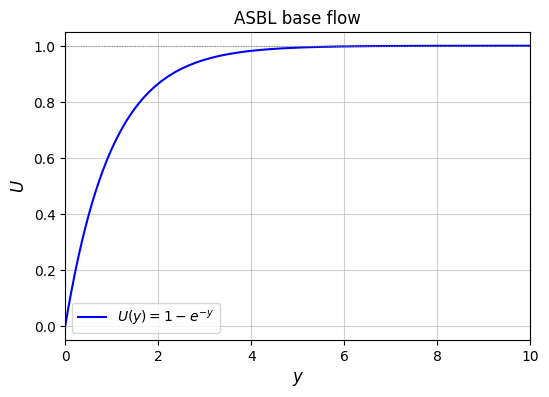

In [4]:
U   = 1.0 - np.exp(-y)
Upp = -np.exp(-y)           # U''(y)

fig = plt.figure()
plt.plot(y, U, 'b', label=r'$U(y)=1-e^{-y}$')
plt.axhline(1.0, color='gray', lw=0.7, ls=':')
plt.xlim([0, 10])
plt.xlabel(r'$y$')
plt.ylabel(r'$U$')
plt.legend()
plt.title('ASBL base flow')
plt.grid()
plt.show()

**Construct the Orr&ndash;Sommerfeld operators $A$ and $B$:**
Same structure as channel flow, plus the extra suction term $-\frac{1}{Re}(D^3-\alpha^2 D)$
derived above.

In [5]:
# A*vhat = omega*B*vhat
I = np.identity(N)
D2m = D2 - alpha**2*I                      # (D^2 - alpha^2 I)
D4m = D4 - 2*alpha**2*D2 + alpha**4*I      # (D^2 - alpha^2 I)^2

A = -D4m/Re + 1j*alpha*np.diag(U)@D2m - 1j*alpha*np.diag(Upp)
A += -(D3 - alpha**2*D1)/Re                # <-- the new suction term
B = 1j*D2m

Set the boundary conditions: no-slip/no-penetration at the wall, and decay of the disturbance
in the far field &mdash; both give $\hat v=\hat v'=0$:

$$
\hat v(y=0)=\hat v'(y=0)=0\,,\qquad \hat v(y=y_{\max})=\hat v'(y=y_{\max})=0\,,
$$

imposed by the same row-replacement trick as for channel flow.

In [6]:
# move the eigenvalues of the BC to Q
Q = -999j
# two homogeneous Dirichlet conditions (wall, far field)
A[0,:]  = Q*I[0,:];   B[0,:]  = I[0,:]
A[-1,:] = Q*I[-1,:];  B[-1,:] = I[-1,:]
# two homogeneous Neumann conditions (wall, far field)
A[1,:]  = Q*D1[0,:];  B[1,:]  = D1[0,:]
A[-2,:] = Q*D1[-1,:]; B[-2,:] = D1[-1,:]

**Solve the eigenvalue problem:** generalised eigenvalue problem, as before.

In [7]:
# compute eigenvalues and eigenvectors (A*vhat = omega*B*vhat)
omega, vv = scla.eig(A, B)
c = omega/alpha

# discard the huge (Q-related, boundary-condition) eigenvalues
valid = np.abs(omega) < 100
omega, c, vv = omega[valid], c[valid], vv[:, valid]

The eigenvalue (and eigenfunction) with the largest growth rate ($\mathrm{Im}(\omega)$, or
equivalently $\mathrm{Im}(c)$ since $\alpha>0$) is the leading Tollmien&ndash;Schlichting-type mode
&mdash; **with one caveat that has no analogue in channel flow.** Truncating the semi-infinite
domain discretizes the *continuous spectrum* associated with the free stream, which produces a
cluster of eigenvalues near $c_r=1$ (visible as a tight group in the spectrum plot below). These are
numerical representations of a genuine physical continuous spectrum, but they are not the
instability we are after, and at low growth rates they can sit right next to (or even above) the
true Tollmien&ndash;Schlichting eigenvalue in $\mathrm{Im}(\omega)$. We therefore restrict the search
for the leading mode to $c_r<0.9$, away from the free-stream cluster. As before, $u$ is obtained
from continuity, and the eigenfunctions are rescaled so the maximum of $u$ is real.

In [8]:
physical = c.real < 0.9   # exclude the discretised free-stream continuous spectrum (c_r~1)
i = np.where(physical)[0][np.argmax(omega[physical].imag)]
cmax = c[i]

v = vv[:,i]
u = -np.dot(D1, v)/(1j*alpha)   # continuity: i alpha u + Dv = 0

# rescale
j = np.argmax(abs(u))
w = u[j]
u /= w
v /= w

print('Leading eigenvalue c     = ', cmax)
print('Leading eigenvalue omega = ', cmax*alpha)

Leading eigenvalue c     =  (0.13219543748971627+0.002104323152116901j)
Leading eigenvalue omega =  (0.01982931562345744+0.00031564847281753515j)


Plot the eigenvalue spectrum and the eigenfunctions for $u$ and $v$.

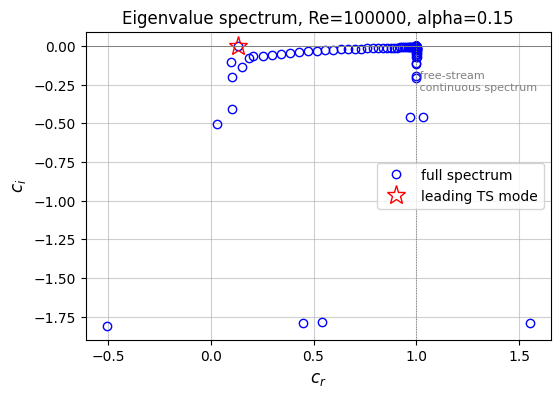

In [9]:
fig = plt.figure()
plt.plot(c.real, c.imag, 'ob', mfc='none', label='full spectrum')
plt.plot(cmax.real, cmax.imag, 'r*', ms=14, label='leading TS mode')
plt.axhline(0, color='gray', lw=0.7)
plt.axvline(1.0, color='gray', lw=0.7, ls=':')
plt.text(1.0, plt.ylim()[0]*0.15, ' free-stream\n continuous spectrum', fontsize=8, color='gray')
plt.grid()
plt.xlabel('$c_r$')
plt.ylabel('$c_i$')
plt.legend()
plt.title(f'Eigenvalue spectrum, Re={Re:.0f}, alpha={alpha}')
plt.show()

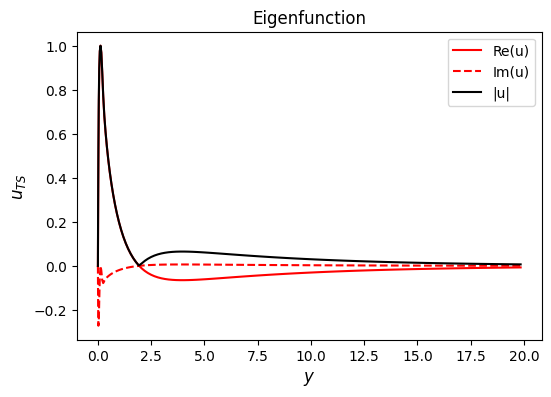

In [10]:
fig = plt.figure()
mask = y < 20
plt.plot(y[mask], u.real[mask], 'r', label='Re(u)')
plt.plot(y[mask], u.imag[mask], 'r--', label='Im(u)')
plt.plot(y[mask], abs(u[mask]), 'k-', label='|u|')
plt.legend(loc='best')
plt.xlabel(r'$y$')
plt.ylabel(r'$u_{TS}$')
plt.title('Eigenfunction')
plt.show()

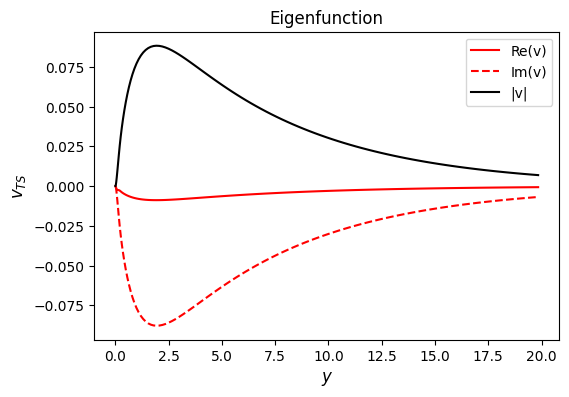

In [11]:
fig = plt.figure()
mask = y < 20
plt.plot(y[mask], v.real[mask], 'r', label='Re(v)')
plt.plot(y[mask], v.imag[mask], 'r--', label='Im(v)')
plt.plot(y[mask], abs(v[mask]), 'k-', label='|v|')
plt.xlabel(r'$y$')
plt.ylabel(r'$v_{TS}$')
plt.legend(loc='best')
plt.title('Eigenfunction')
plt.show()

## Validation against published results

Two independent checks against the literature:

1. **With** the suction term, at the published critical point $Re_c=54\,378.62$,
   $\alpha_c=0.15546$ (Yalcin, T&uuml;rka&ccedil; &amp; Oberlack, *Phys. Fluids* 2021, refining
   Fransson &amp; Alfredsson 2003), the leading eigenvalue should have $\omega_i\approx0$ and
   $\omega_r\approx0.023297$.
2. **Without** the suction term (i.e. solving the *unmodified* Orr&ndash;Sommerfeld equation with
   the ASBL profile substituted in, as Hughes &amp; Reid did in 1965), the neutral point should
   shift to $Re_c\approx47\,047$ at $\alpha\approx0.163$.

Both are reproduced below using a compact version of the solver above, wrapped in a function so it
can be called repeatedly.

In [12]:
def solve_ASBL(Re, alpha, N, Ymax, suction_term=True):
    # leading eigenvalue omega of the (modified) ASBL Orr-Sommerfeld problem
    x, DM = chebdif(N, 4)
    D1x, D2x, D3x, D4x = DM[0], DM[1], DM[2], DM[3]
    J = 2.0/Ymax
    D1, D2, D3, D4 = -J*D1x, J**2*D2x, -J**3*D3x, J**4*D4x
    y = Ymax*(1-x)/2.0

    U, Upp = 1.0-np.exp(-y), -np.exp(-y)
    I = np.identity(N)
    D2m = D2 - alpha**2*I
    D4m = D4 - 2*alpha**2*D2 + alpha**4*I

    A = -D4m/Re + 1j*alpha*np.diag(U)@D2m - 1j*alpha*np.diag(Upp)
    if suction_term:
        A += -(D3 - alpha**2*D1)/Re
    B = 1j*D2m

    Q = -999j
    A[0,:]=Q*I[0,:];   B[0,:]=I[0,:]
    A[-1,:]=Q*I[-1,:]; B[-1,:]=I[-1,:]
    A[1,:]=Q*D1[0,:];  B[1,:]=D1[0,:]
    A[-2,:]=Q*D1[-1,:];B[-2,:]=D1[-1,:]

    omega, _ = scla.eig(A, B)
    c = omega/alpha
    # drop BC artifacts and the discretised free-stream continuous spectrum (c_r~1)
    physical = (np.abs(omega) < 100) & (c.real < 0.9)
    omega = omega[physical]
    return omega[np.argmax(omega.imag)]

om1 = solve_ASBL(54378.62, 0.15546, 200, 40.0, suction_term=True)
print(f'With suction term,    Re=54378.62, alpha=0.15546:  omega = {om1:.6f}   (lit: 0.023297 + 0.000000j)')

om2 = solve_ASBL(47047, 0.163, 200, 40.0, suction_term=False)
print(f'Without suction term, Re=47047,    alpha=0.163   :  omega = {om2:.6f}   (Hughes & Reid 1965: c_i approx 0)')

With suction term,    Re=54378.62, alpha=0.15546:  omega = 0.023296-0.000000j   (lit: 0.023297 + 0.000000j)
Without suction term, Re=47047,    alpha=0.163   :  omega = 0.025420-0.000001j   (Hughes & Reid 1965: c_i approx 0)


## Numerical convergence

The domain truncation and mapping introduce two numerical parameters with no analogue in the
channel-flow problem: the number of collocation points $N$, and the truncation length $y_{\max}$.
Both are checked for convergence at the critical point.

In [13]:
print('Convergence with N (Ymax=40 fixed):')
for Ntest in [80,120,160,200,250,300]:
    om = solve_ASBL(54378.62, 0.15546, Ntest, 40.0)
    print(f'  N={Ntest:4d}   omega = {om:.6f}')

print()
print('Convergence with Ymax (N=200 fixed):')
for Ytest in [15,20,25,30,40,50,70]:
    om = solve_ASBL(54378.62, 0.15546, 200, Ytest)
    print(f'  Ymax={Ytest:5.1f}   omega = {om:.6f}')

Convergence with N (Ymax=40 fixed):
  N=  80   omega = 0.023367+0.000057j
  N= 120   omega = 0.023284+0.000008j
  N= 160   omega = 0.023294-0.000001j
  N= 200   omega = 0.023296-0.000000j
  N= 250   omega = 0.023296-0.000000j
  N= 300   omega = 0.023296-0.000000j

Convergence with Ymax (N=200 fixed):
  Ymax= 15.0   omega = 0.023465-0.000024j
  Ymax= 20.0   omega = 0.023332-0.000005j
  Ymax= 25.0   omega = 0.023303-0.000001j
  Ymax= 30.0   omega = 0.023297-0.000000j
  Ymax= 40.0   omega = 0.023296-0.000000j
  Ymax= 50.0   omega = 0.023296+0.000001j
  Ymax= 70.0   omega = 0.023293+0.000002j


## Neutral stability curve for the ASBL

As for channel flow, compute the contours of $\max(\omega_i)$ over a grid of $(Re,\alpha)$; the
$\max(\omega_i)=0$ isoline is the **neutral stability curve**. Create the mesh:

In [14]:
N_Re = 28
N_alpha = 28
RE, ALPHA = np.meshgrid(np.linspace(20000, 200000, N_Re), np.linspace(0.05, 0.28, N_alpha))

Compute $\max(\omega_i)$ for every $(Re,\alpha)$ in the mesh (uses a smaller $N$ than above
to keep the run time reasonable; the neutral curve location is already well converged at this
resolution &mdash; see the convergence check above).

In [15]:
g = np.zeros((N_alpha, N_Re))
for ii in range(N_Re):
    for jj in range(N_alpha):
        g[jj,ii] = solve_ASBL(RE[jj,ii], ALPHA[jj,ii], 150, 40.0).imag

Plot the contours of $\max(\omega_i)$, with a solid contour line at $\max(\omega_i)=0$, and
compare to the refined critical point of Yalcin, T&uuml;rka&ccedil; &amp; Oberlack (2021)
/ Fransson &amp; Alfredsson (2003).

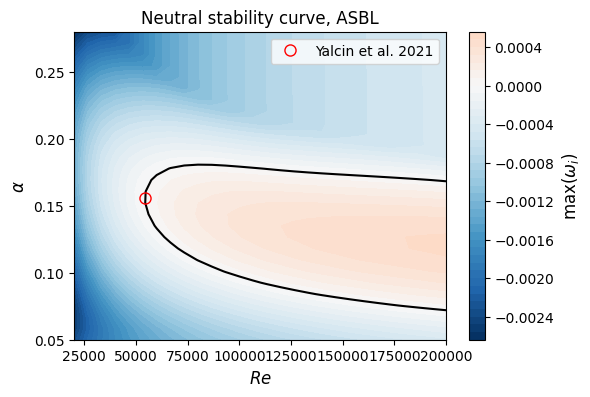

In [16]:
fig = plt.figure()
CS = plt.contourf(RE[0,:], ALPHA[:,0], g, levels=40, cmap='RdBu_r',
                   vmin=-np.max(np.abs(g)), vmax=np.max(np.abs(g)))
plt.colorbar(label=r'$\max(\omega_i)$')
CS1 = plt.contour(RE[0,:], ALPHA[:,0], g, levels=[0], colors='k')
plt.xlabel(r'$Re$')
plt.ylabel(r'$\alpha$')
plt.plot(54378.62, 0.15546, 'ro', ms=8, label='Yalcin et al. 2021')
plt.legend()
plt.title('Neutral stability curve, ASBL')
plt.show()